In [1]:
%pip install -q langgraph langchain langchain-google-genai langchain-core

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os

try:
    from kaggle_secrets import UserSecretsClient
    # Hugging Face libraries automatically look for "HF_TOKEN"
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    print(" Hugging Face token loaded from Kaggle Secrets")
except Exception as e:
    # If you aren't running in a Kaggle notebook environment, paste your fallback key below
    os.environ["HF_TOKEN"] = "enter your Hugging Face API key here"
    print(" Using manually set Hugging Face API key")

 Using manually set Hugging Face API key


In [14]:
import sqlite3

DB_PATH = "company.db"

if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

cur.execute("""
    CREATE TABLE departments (
        id INTEGER PRIMARY KEY, name TEXT NOT NULL, location TEXT NOT NULL
    )
""")
cur.executemany("INSERT INTO departments VALUES (?, ?, ?)", [
    (1, "Engineering", "San Francisco"), (2, "Marketing", "New York"),
    (3, "Sales", "Chicago"), (4, "Human Resources", "San Francisco"),
    (5, "Finance", "New York"),
])

cur.execute("""
    CREATE TABLE employees (
        id INTEGER PRIMARY KEY, name TEXT NOT NULL, department_id INTEGER NOT NULL,
        salary REAL NOT NULL, hire_date TEXT NOT NULL,
        FOREIGN KEY (department_id) REFERENCES departments(id)
    )
""")
cur.executemany("INSERT INTO employees VALUES (?, ?, ?, ?, ?)", [
    (1, "Alice Johnson", 1, 120000, "2020-03-15"),
    (2, "Bob Smith", 1, 95000, "2021-07-01"),
    (3, "Carol Williams", 2, 85000, "2019-11-20"),
    (4, "David Brown", 3, 78000, "2022-01-10"),
    (5, "Eve Davis", 1, 110000, "2020-09-05"),
    (6, "Frank Miller", 4, 72000, "2018-06-12"),
    (7, "Grace Wilson", 5, 98000, "2021-02-28"),
    (8, "Henry Taylor", 3, 82000, "2023-04-17"),
    (9, "Ivy Anderson", 2, 91000, "2020-08-22"),
    (10, "Jack Thomas", 1, 105000, "2022-11-03"),
])

cur.execute("""
    CREATE TABLE projects (
        id INTEGER PRIMARY KEY, name TEXT NOT NULL, department_id INTEGER NOT NULL,
        budget REAL NOT NULL, status TEXT NOT NULL,
        FOREIGN KEY (department_id) REFERENCES departments(id)
    )
""")
cur.executemany("INSERT INTO projects VALUES (?, ?, ?, ?, ?)", [
    (1, "AI Platform", 1, 500000, "active"),
    (2, "Brand Refresh", 2, 150000, "active"),
    (3, "Q3 Sales Campaign", 3, 200000, "completed"),
    (4, "Employee Wellness", 4, 80000, "active"),
    (5, "Budget Optimization", 5, 120000, "planning"),
    (6, "Cloud Migration", 1, 350000, "active"),
])

conn.commit()
conn.close()
print(" Database created with 3 tables: departments, employees, projects")

 Database created with 3 tables: departments, employees, projects


In [15]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd

conn = sqlite3.connect(DB_PATH)
for table in ["departments", "employees", "projects"]:
    print(f"\n {table.upper()}:")
    display(pd.read_sql(f"SELECT * FROM {table}", conn))
conn.close()


 DEPARTMENTS:


,id,name,location
0,1,Engineering,San Francisco
1,2,Marketing,New York
2,3,Sales,Chicago
3,4,Human Resources,San Francisco
4,5,Finance,New York



 EMPLOYEES:


,id,name,department_id,salary,hire_date
0,1,Alice Johnson,1,120000.0,2020-03-15
1,2,Bob Smith,1,95000.0,2021-07-01
2,3,Carol Williams,2,85000.0,2019-11-20
3,4,David Brown,3,78000.0,2022-01-10
4,5,Eve Davis,1,110000.0,2020-09-05
5,6,Frank Miller,4,72000.0,2018-06-12
6,7,Grace Wilson,5,98000.0,2021-02-28
7,8,Henry Taylor,3,82000.0,2023-04-17
8,9,Ivy Anderson,2,91000.0,2020-08-22
9,10,Jack Thomas,1,105000.0,2022-11-03



 PROJECTS:


,id,name,department_id,budget,status
0,1,AI Platform,1,500000.0,active
1,2,Brand Refresh,2,150000.0,active
2,3,Q3 Sales Campaign,3,200000.0,completed
3,4,Employee Wellness,4,80000.0,active
4,5,Budget Optimization,5,120000.0,planning
5,6,Cloud Migration,1,350000.0,active


In [23]:
import textwrap
from typing import Literal
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

class AgentState(BaseModel):
    question:    str       = Field(description="User's natural-language question")
    schema:      str       = Field(default="")
    sql_query:   str       = Field(default="")
    results:     list      = Field(default_factory=list)
    columns:     list[str] = Field(default_factory=list)
    answer:      str       = Field(default="")
    error:       str       = Field(default="")
    retry_count: int       = Field(default=0)

# Filled the active model name and attached max_retries to handle rate limits gracefully
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash", 
    temperature=0,
    max_retries=5  # Smoothly backs off and retries if the free tier hits a 429 limit
)

MAX_RETRIES = 2
print(" LLM and state ready")

C:\Users\dell\AppData\Local\Temp\ipykernel_26672\3086060867.py:8: UserWarning: Field name "schema" in "AgentState" shadows an attribute in parent "BaseModel"
  class AgentState(BaseModel):


 LLM and state ready


In [41]:
def get_database_schema():
    conn = sqlite3.connect(DB_PATH)
    cur = conn.cursor()
    cur.execute("SELECT name FROM sqlite_master WHERE type='table'")
    tables = [row[0] for row in cur.fetchall()]
    parts = []
    for table in tables:
        cur.execute(f"SELECT sql FROM sqlite_master WHERE name='{table}'")
        parts.append(cur.fetchone()[0] + ";")
    conn.close()
    return "\n\n".join(parts)

def get_schema(state: AgentState) -> dict:
    return {"schema": get_database_schema()}

import os
from pathlib import Path
from dotenv import dotenv_values
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

def generate_sql(state: AgentState):
    print("---GENERATE SQL (via Groq Override)---")
    
    # 1. Manually parse the .env file directly from disk
    env_path = Path(os.getcwd()) / ".env"
    env_dict = dotenv_values(dotenv_path=env_path)
    
    # 2. Extract the key directly from the parsed dictionary
    groq_key = env_dict.get("GROQ_API_KEY")
    
    # Fallback to os.environ if the dictionary check fails
    if not groq_key:
        groq_key = os.environ.get("GROQ_API_KEY")
        
    if not groq_key:
        raise ValueError("GROQ_API_KEY is completely missing from both the .env file and environment paths!")
    
    # 3. Instantiate ChatGroq cleanly
    groq_llm = ChatGroq(
        model_name="llama-3.1-8b-instant", 
        temperature=0,
        api_key=groq_key
    )
    
    system_prompt = (
        "You are an expert SQL developer. Given a database schema, write a valid SQLite query "
        "to answer the user's question. Return ONLY the raw SQL query, no markdown formatting."
    )
    user_prompt = f"Schema:\n{state.schema}\n\nQuestion: {state.question}"
    
    response = groq_llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ])
    
    sql_clean = response.content.replace("```sql", "").replace("```", "").strip()
    
    return {"sql_query": sql_clean}

def execute_sql(state: AgentState) -> dict:
    try:
        conn = sqlite3.connect(DB_PATH)
        cur = conn.cursor()
        cur.execute(state.sql_query)
        columns = [desc[0] for desc in cur.description] if cur.description else []
        results = cur.fetchall()
        conn.close()
        return {"results": results, "columns": columns, "error": ""}
    except Exception as exc:
        return {"results": [], "columns": [], "error": str(exc)}

def handle_error(state: AgentState) -> dict:
    return {"retry_count": state.retry_count + 1}

import os
from pathlib import Path
from dotenv import dotenv_values
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

def format_response(state: AgentState):
    print("---FORMAT RESPONSE (via Groq Override)---")
    
    # 1. Manually pull the Groq key from disk
    env_path = Path(os.getcwd()) / ".env"
    env_dict = dotenv_values(dotenv_path=env_path)
    groq_key = env_dict.get("GROQ_API_KEY") or os.environ.get("GROQ_API_KEY")
    
    if not groq_key:
        raise ValueError("GROQ_API_KEY is missing from your environment configuration!")
    
    # 2. Set up the Groq LLM
    groq_llm = ChatGroq(
        model_name="llama-3.1-8b-instant", 
        temperature=0,
        api_key=groq_key
    )
    
    # 3. Formulate the prompt using the query and executed data rows in the state
    system_prompt = (
        "You are an assistant that summarizes database query results into clear natural language. "
        "Provide a direct, conversational response to the user's question based strictly on the results provided."
    )
    user_prompt = (
        f"Question: {state.question}\n"
        f"SQL Query Executed: {state.sql_query}\n"
        f"Database Results: {state.results}\n"
    )
    
    # 4. Invoke the model
    response = groq_llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ])
    
    return {"answer": response.content}

print(" All graph nodes defined")

 All graph nodes defined


 LangGraph agent compiled!


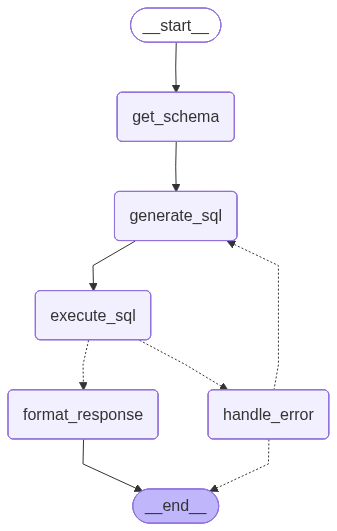

In [42]:
def route_after_execution(state: AgentState) -> Literal["format_response", "handle_error"]:
    return "handle_error" if state.error else "format_response"

def route_after_error(state: AgentState) -> Literal["generate_sql", "__end__"]:
    return "generate_sql" if state.retry_count < MAX_RETRIES else END

graph = StateGraph(AgentState)
graph.add_node("get_schema", get_schema)
graph.add_node("generate_sql", generate_sql)
graph.add_node("execute_sql", execute_sql)
graph.add_node("handle_error", handle_error)
graph.add_node("format_response", format_response)

graph.add_edge(START, "get_schema")
graph.add_edge("get_schema", "generate_sql")
graph.add_edge("generate_sql", "execute_sql")
graph.add_conditional_edges("execute_sql", route_after_execution)
graph.add_conditional_edges("handle_error", route_after_error)
graph.add_edge("format_response", END)

agent = graph.compile()
print(" LangGraph agent compiled!")

# Visualize the graph
try:
    from IPython.display import Image, display
    display(Image(agent.get_graph().draw_mermaid_png()))
except:
    print("(Graph visualization not available)")

In [43]:
from IPython.display import Markdown, display as idisplay

def ask(question: str):
    print("═" * 70)
    print(f" QUESTION: {question}")
    print("═" * 70)

    for step in agent.stream(AgentState(question=question).model_dump()):
        node_name = list(step.keys())[0]
        out = step[node_name]

        if node_name == "get_schema":
            print(f"\n Schema retrieved")
        elif node_name == "generate_sql":
            print(f"\n Generated SQL:\n   {out.get('sql_query', '')}")
        elif node_name == "execute_sql":
            if out.get("error"):
                print(f"\n Error: {out['error']}")
            else:
                print(f"\n Query returned {len(out.get('results', []))} row(s)")
        elif node_name == "handle_error":
            print(f"\n Retrying... ({out.get('retry_count')}/{MAX_RETRIES})")
        elif node_name == "format_response":
            print(f"\n ANSWER:")
            idisplay(Markdown(out.get("answer", "")))

    print("═" * 70)

In [44]:
ask("What is the average salary in the Engineering department?")

══════════════════════════════════════════════════════════════════════
 QUESTION: What is the average salary in the Engineering department?
══════════════════════════════════════════════════════════════════════

 Schema retrieved
---GENERATE SQL (via Groq Override)---

 Generated SQL:
   SELECT AVG(T1.salary) FROM employees AS T1 INNER JOIN departments AS T2 ON T1.department_id = T2.id WHERE T2.name = 'Engineering'

 Query returned 1 row(s)
---FORMAT RESPONSE (via Groq Override)---

 ANSWER:


The average salary in the Engineering department is $107,500.

══════════════════════════════════════════════════════════════════════


In [45]:
ask("List all active projects along with their department names and budgets.")

══════════════════════════════════════════════════════════════════════
 QUESTION: List all active projects along with their department names and budgets.
══════════════════════════════════════════════════════════════════════

 Schema retrieved
---GENERATE SQL (via Groq Override)---

 Generated SQL:
   SELECT p.name, d.name AS department_name, p.budget 
FROM projects p 
JOIN departments d ON p.department_id = d.id 
WHERE p.status = 'active';

 Query returned 4 row(s)
---FORMAT RESPONSE (via Groq Override)---

 ANSWER:


Based on the database results, here are the active projects along with their department names and budgets:

We have four active projects currently underway. 

1. The 'AI Platform' project, which falls under the Engineering department, has a budget of $500,000.
2. The 'Brand Refresh' project, managed by the Marketing department, has a budget of $150,000.
3. The 'Employee Wellness' project, handled by the Human Resources department, has a budget of $80,000.
4. The 'Cloud Migration' project, also under the Engineering department, has a budget of $350,000.

These projects are currently active and ongoing.

══════════════════════════════════════════════════════════════════════


In [46]:
ask("Who are the top 3 highest-paid employees and which departments do they belong to?")

══════════════════════════════════════════════════════════════════════
 QUESTION: Who are the top 3 highest-paid employees and which departments do they belong to?
══════════════════════════════════════════════════════════════════════

 Schema retrieved
---GENERATE SQL (via Groq Override)---

 Generated SQL:
   SELECT e.name, d.name AS department_name, e.salary FROM employees e INNER JOIN departments d ON e.department_id = d.id ORDER BY e.salary DESC LIMIT 3

 Query returned 3 row(s)
---FORMAT RESPONSE (via Groq Override)---

 ANSWER:


Based on the database results, the top 3 highest-paid employees are:

1. Alice Johnson from the Engineering department with a salary of $120,000.
2. Eve Davis from the Engineering department with a salary of $110,000.
3. Jack Thomas from the Engineering department with a salary of $105,000.

It's worth noting that all three of the highest-paid employees belong to the Engineering department.

══════════════════════════════════════════════════════════════════════


In [47]:
ask("Which department has the most employees?")

══════════════════════════════════════════════════════════════════════
 QUESTION: Which department has the most employees?
══════════════════════════════════════════════════════════════════════

 Schema retrieved
---GENERATE SQL (via Groq Override)---

 Generated SQL:
   SELECT name FROM departments WHERE id IN ( SELECT department_id FROM employees GROUP BY department_id ORDER BY COUNT(department_id) DESC LIMIT 1 );

 Query returned 1 row(s)
---FORMAT RESPONSE (via Groq Override)---

 ANSWER:


The department with the most employees is Engineering.

══════════════════════════════════════════════════════════════════════
